# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Victor Henz  Student ID: B00817998
2. Full name: Edgar Gusching  Student ID: B00822088
3. Full name: Marius Rang  Student ID: B00821794
4. Full name: Ylias Guetari  Student ID: B00824832

**Project role (consultant / data scientist / risk analyst):** Consultant (sustainability consultant)
**Key quantity (one sentence, with unit):** RWE's operating wind + solar capacity (equity share, GW), rebuilt year by year from GEM start years, and its 2030 value, which we turn into the capacity-factor-adjusted replacement ratio against the coal (and gas) RWE has to retire by 2030.
**Repo URL:** _______________

## Setup (given)

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # GEM Global Integrated Power Tracker (Sept 2026 V2), one row per unit/phase
    DATA_CANDIDATES = [
        Path("../data/Global Integrated Power September 2026 V2.xlsx"),  # repo: data/
        Path("Global Integrated Power September 2026 V2.xlsx"),          # next to the notebook
    ]
    DATA = next(p for p in DATA_CANDIDATES if p.exists())
    cols = ["Type", "Country/area", "Plant / Project name", "Unit / Phase name",
            "Capacity (MW)", "Status", "Start year", "Retired year", "Technology",
            "Fuel (combustion only)", "Owner(s)", "Parent(s)"]
    gipt = pd.read_excel(DATA, sheet_name="Power facilities", usecols=cols)

    # keep every unit where RWE (or one of its subsidiaries) shows up as owner or parent
    is_rwe = (gipt["Owner(s)"].fillna("").str.contains("RWE")
              | gipt["Parent(s)"].fillna("").str.contains("RWE"))
    rwe = gipt[is_rwe].copy()

    def rwe_share(row):
        # equity share of RWE in the unit: sum of the % next to the RWE entities.
        # parent column first (already consolidated), owner column if no parent.
        # if a % is missing we split equally between the listed owners.
        txt = row["Parent(s)"] if "RWE" in str(row["Parent(s)"]) else row["Owner(s)"]
        parts = [p.strip() for p in str(txt).split(";") if p.strip()]
        shares = []
        for p in parts:
            if "RWE" in p:
                m = re.search(r"\[([\d.]+)%\]", p)
                if m is None:
                    return 1 / len(parts)
                shares.append(float(m.group(1)) / 100)
        return min(sum(shares), 1.0)

    rwe["share"] = rwe.apply(rwe_share, axis=1)
    rwe["mw_eq"] = rwe["Capacity (MW)"] * rwe["share"]   # equity-weighted MW

    RE = ["wind", "utility-scale solar"]
    FOSSIL = ["coal", "oil/gas"]

    # quick data audit (the checks we promised in the project definition)
    audit = pd.Series({
        "units linked to RWE": len(rwe),
        "share with capacity": rwe["Capacity (MW)"].notna().mean(),
        "share with parent recorded": rwe["Parent(s)"].notna().mean(),
        "share of built wind/solar MW with start year": (
            rwe.loc[rwe.Type.isin(RE) & rwe.Status.isin(["operating", "retired"])]
               .pipe(lambda d: d.loc[d["Start year"].notna(), "mw_eq"].sum() / d["mw_eq"].sum())),
        "share of operating fossil units with retirement date": (
            rwe.loc[rwe.Type.isin(FOSSIL) & (rwe.Status == "operating"), "Retired year"].notna().mean()),
    })
    print(audit.round(2).to_string(), "\n")

    # rebuild RWE's operating wind + solar capacity at the end of each year
    # (unit counts if it started that year or before and is not retired yet)
    built = rwe[rwe.Type.isin(RE) & rwe.Status.isin(["operating", "retired"])
                & rwe["Start year"].notna()]
    years = np.arange(2005, 2026)
    values = [built.loc[(built["Start year"] <= y) & ~(built["Retired year"] <= y), "mw_eq"].sum() / 1000
              for y in years]
    series = pd.DataFrame({"year": years.astype(int), "value": np.array(values, dtype=float)})
    NAME = "RWE operating wind + solar capacity (equity share)"
    UNIT = "GW"

assert series["year"].is_unique and series["year"].is_monotonic_increasing
print(NAME, f"[{UNIT}]", "-", len(series), "years")
series.tail()

units linked to RWE                                    522.00
share with capacity                                      1.00
share with parent recorded                               0.28
share of built wind/solar MW with start year             0.98
share of operating fossil units with retirement date     0.19 

RWE operating wind + solar capacity (equity share) [GW] - 21 years


,year,value
16,2021,8.66
17,2022,10.61
18,2023,11.28
19,2024,11.61
20,2025,12.64


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our quantity is RWE's operating wind + solar capacity in GW (equity share), rebuilt from the GEM Integrated Power Tracker, plus where it lands in 2030. It feeds our consultant question: is RWE on track for its 2030 coal exit, i.e. is the replacement ratio (new wind/solar TWh ÷ retiring fossil TWh) ≥ 1, and is the pipeline credible compared with what RWE has actually built? Main uncertainties: how much of the pipeline really gets built by 2030 (**E**: we don't know RWE's execution, permits, supply chain), the yearly capacity factors of wind and solar (**A**: weather), the ownership data (**E**: only 28% of RWE units have a parent recorded, and acquired assets look like RWE built them) and auction results / policy / RWE's own capex choices (**S**).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model="linear", level=0.90):
    """OLS trend on train (year, value), returns the next `horizon` years
    with the mean and a Student-t prediction interval."""
    x = train["year"].to_numpy(float)
    y = train["value"].to_numpy(float)
    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs all values > 0")
        y = np.log(y)
    elif model != "linear":
        raise ValueError(f"unknown model {model}")

    xbar = x.mean()
    X = np.column_stack([np.ones_like(x), x - xbar])          # centred year
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    n, p = X.shape
    s = np.sqrt(resid @ resid / (n - p))                       # residual std

    fut = np.arange(x.max() + 1, x.max() + 1 + horizon)
    X0 = np.column_stack([np.ones(horizon), fut - xbar])
    mean = X0 @ beta
    leverage = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)       # x0'(X'X)^-1 x0
    tq = stats.t.ppf(0.5 + level / 2, df=n - p)
    half = tq * s * np.sqrt(1 + leverage)
    lo, hi = mean - half, mean + half

    if model == "loglinear":                                   # back to GW (mean = median on the log scale)
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)
    return pd.DataFrame({"year": fut.astype(int), "mean": mean, "lo": lo, "hi": hi})


# hold out the last 5 years
H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
backtest = pd.concat(
    [fit_predict(train, H, m).assign(model=m) for m in ["linear", "loglinear"]],
    ignore_index=True,
).merge(test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = backtest["actual"].between(backtest["lo"], backtest["hi"])
backtest = backtest[["model", "year", "actual", "mean", "lo", "hi", "inside"]]
print(f"train {train.year.min()}-{train.year.max()}, test {test.year.min()}-{test.year.max()}")
backtest

train 2005-2020, test 2021-2025


,model,year,actual,mean,lo,hi,inside
0,linear,2021,8.66,8.29,7.72,8.86,True
1,linear,2022,10.61,8.78,8.20,9.37,False
2,linear,2023,11.28,9.28,8.68,9.87,False
3,linear,2024,11.61,9.77,9.16,10.38,False
4,linear,2025,12.64,10.27,9.65,10.89,False
5,loglinear,2021,8.66,13.14,6.79,25.41,True
6,loglinear,2022,10.61,15.55,7.93,30.48,True
7,loglinear,2023,11.28,18.39,9.24,36.60,True
8,loglinear,2024,11.61,21.76,10.77,44.00,True
9,loglinear,2025,12.64,25.75,12.53,52.95,True


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

           hits  n  coverage
model                       
linear        1  5      0.20
loglinear     5  5      1.00 

 misses k  P(X >= k)
        0       1.00
        1       0.41
        2       0.08
        3       0.01
        4       0.00
        5       0.00


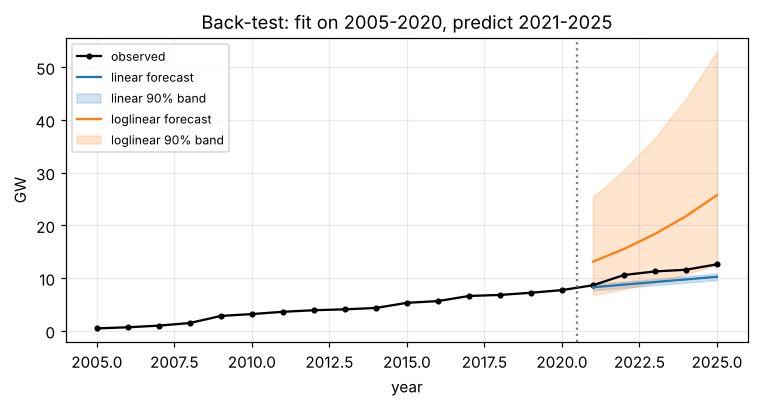

In [4]:
# (a) coverage per model
cover = backtest.groupby("model")["inside"].agg(hits="sum", n="count")
cover["coverage"] = cover["hits"] / cover["n"]
print(cover, "\n")

# (b) how many misses out of 5 are suspicious for a 90% band? X ~ Bin(5, 0.1)
k = np.arange(0, 6)
binom_tab = pd.DataFrame({"misses k": k, "P(X >= k)": stats.binom.sf(k - 1, 5, 0.1)})
print(binom_tab.to_string(index=False))

# plot of the back-test
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(series.year, series.value, "k.-", label="observed")
for m, c in [("linear", "tab:blue"), ("loglinear", "tab:orange")]:
    b = backtest[backtest.model == m]
    ax.plot(b.year, b["mean"], color=c, label=f"{m} forecast")
    ax.fill_between(b.year, b.lo, b.hi, color=c, alpha=0.2, label=f"{m} 90% band")
ax.axvline(train.year.max() + 0.5, color="grey", ls=":")
ax.set(xlabel="year", ylabel=f"{UNIT}", title="Back-test: fit on 2005-2020, predict 2021-2025")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Your answer (Q2):**

(a) The linear model only got **1 out of 5** held-out years (2021) inside its 90% band; the log-linear one got **5 out of 5**, but only because its band is huge (12.5 to 53 GW in 2025, the median even says 25.8 GW when the truth is 12.6 GW).

(b) For X ~ Bin(5, 0.1): P(X ≥ 1) = 0.41, P(X ≥ 2) = 0.08, P(X ≥ 3) = 0.01. So already **2 misses** would make us doubt a 90% band (less than a 10% chance), and 3 or more is a clear fail. The linear model has 4 misses (P ≈ 0.0005), so its band is way too narrow. The rolling back-test says the same: linear coverage is 73% / 60% / 56% at 1 / 2 / 3 years ahead, log-linear is 100% / 100% / 67%.

(c) If we have to keep one, it's the log-linear one since it's the only one that passes, but honestly neither is useful: the linear band is overconfident (RWE sped up after 2021) and the log-linear band is too wide to say anything. The gap between them shows that the uncertainty comes mostly from the **model choice**, not the noise. So for 2030 we don't extrapolate a trend at all, we build the number bottom-up from the project pipeline (Part C).

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# rolling origin: fit on all years up to the cutoff, predict 1-3 years ahead
rows = []
for i in range(10, len(series)):                 # first cutoff = 10th year
    tr = series.iloc[:i]
    for m in ["linear", "loglinear"]:
        pred = fit_predict(tr, 3, m).merge(series, on="year")   # drops years we don't observe
        for h, r in enumerate(pred.itertuples(), start=1):
            rows.append({"model": m, "cutoff": tr.year.max(), "h": h,
                         "inside": r.lo <= r.value <= r.hi})
roll = pd.DataFrame(rows)
roll_cov = roll.pivot_table(index="model", columns="h", values="inside", aggfunc=["mean", "count"])
roll_cov

mean           count       
h            1    2    3     1   2  3
model                                
linear    0.73 0.60 0.56    11  10  9
loglinear 1.00 1.00 0.67    11  10  9

---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
TARGET = 2030
LIFE = 25                     # assumed lifetime of a wind/solar unit (years)
now = int(series.year.max())
cap_now = series.set_index("year").loc[now, "value"]

# capacity factors (rough European/fleet averages, our assumption)
CF = {"Onshore": 0.25, "Offshore hard mount": 0.40, "Offshore floating": 0.40,
      "Offshore mount unknown": 0.40, "PV": 0.15, "Assumed PV": 0.15}
CF_COAL, CF_GAS = 0.50, 0.40
H_YEAR = 8.76                 # TWh per GW at 100% load

# --- pipeline that could be online by TARGET (equity GW), by stage
pipe = rwe[rwe.Type.isin(RE) & rwe.Status.isin(["construction", "pre-construction", "announced"])
           & ~(rwe["Start year"] > TARGET)].copy()
pipe["cf"] = pipe["Technology"].map(CF)
stage = pipe.groupby("Status").apply(
    lambda d: pd.Series({"GW": d.mw_eq.sum() / 1000,
                         "cf": np.average(d.cf, weights=d.mw_eq)}), include_groups=False)
CON, PRE, ANN = (stage.loc[s, "GW"] for s in ["construction", "pre-construction", "announced"])
P_CON = 0.95                  # construction is almost sure to finish by 2030

# old wind/solar that reaches the end of its life by TARGET
old = built.loc[(built["Start year"] <= TARGET - LIFE) & ~(built["Retired year"] <= now), "mw_eq"].sum() / 1000

# --- fossil capacity to retire by TARGET: all coal (the coal exit) + oil/gas with a retirement date <= TARGET
fos = rwe[rwe.Type.isin(FOSSIL) & (rwe.Status == "operating")]
coal_gw = fos.loc[fos.Type == "coal", "mw_eq"].sum() / 1000
gas_gw = fos.loc[(fos.Type == "oil/gas") & (fos["Retired year"] <= TARGET), "mw_eq"].sum() / 1000
FOSSIL_TWH = (coal_gw * CF_COAL + gas_gw * CF_GAS) * H_YEAR

# --- base rate: of all RWE wind/solar MW that reached a final outcome, how much got built?
outcome = rwe[rwe.Type.isin(RE)].assign(
    built=lambda d: d.Status.isin(["operating", "retired"]),
    dropped=lambda d: d.Status.str.startswith(("cancelled", "shelved")))
base_rate = (outcome.loc[outcome.built, "mw_eq"].sum()
             / outcome.loc[outcome.built | outcome.dropped, "mw_eq"].sum())

print(stage.round(2))
print(f"\ncapacity {now}: {cap_now:.2f} GW | end-of-life by {TARGET}: {old:.2f} GW")
print(f"fossil to retire: coal {coal_gw:.2f} GW + gas {gas_gw:.2f} GW = {FOSSIL_TWH:.1f} TWh/yr")
print(f"historical base rate (MW built / MW built or dropped): {base_rate:.2f}")

# --- the two inputs we are least sure about
# r_pre: share of pre-construction MW online by 2030 -> Beta(5.5, 4.5), mean 0.55, sd 0.15
#        projects have permits / grid / often a won auction, so better than the 0.42 base rate,
#        but offshore takes 3-5 years to build after FID and RWE cut its capex plan in 2025.
# r_ann: share of announced MW online by 2030 -> Beta(2, 10), mean 0.17, sd 0.10
#        mostly offshore with no permit yet; 6-10 years from announcement to COD is normal,
#        so only a small part can make it before 2030.
DIST = {"r_pre": (5.5, 4.5), "r_ann": (2, 10)}


def draw_inputs(dist, n=N, seed=SEED):
    g = np.random.default_rng(seed)
    return {k: g.beta(a, b, n) for k, (a, b) in dist.items()}


def compute_quantity(r_pre, r_ann):
    """RWE wind + solar capacity in TARGET (GW, equity share)."""
    return cap_now - old + CON * P_CON + PRE * r_pre + ANN * r_ann


def replacement_ratio(r_pre, r_ann):
    """Project metric: CF-adjusted pipeline generation / CF-adjusted fossil to retire."""
    add_twh = (CON * P_CON * stage.loc["construction", "cf"]
               + PRE * r_pre * stage.loc["pre-construction", "cf"]
               + ANN * r_ann * stage.loc["announced", "cf"]) * H_YEAR
    return add_twh / FOSSIL_TWH


def summary(x):
    q05, q50, q95 = np.percentile(x, [5, 50, 95])
    return pd.Series({"median": q50, "p05": q05, "p95": q95, "width": q95 - q05})


inp = draw_inputs(DIST)
q = compute_quantity(inp["r_pre"], inp["r_ann"])
ratio = replacement_ratio(inp["r_pre"], inp["r_ann"])
print(f"\n{TARGET} capacity [GW]:", summary(q).round(2).to_dict())
print(f"{TARGET} replacement ratio:", summary(ratio).round(2).to_dict(),
      f"| P(ratio >= 1) = {(ratio >= 1).mean():.2f}")

# --- one-at-a-time sensitivity: fix one input at its median, keep the other random
def rel_half_width(x):
    s = summary(x)
    return s["width"] / 2 / s["median"]

sens = pd.DataFrame({
    "fixed input": ["none (both random)", "r_pre fixed", "r_ann fixed"],
    "rel. half-width": [
        rel_half_width(q),
        rel_half_width(compute_quantity(np.median(inp["r_pre"]), inp["r_ann"])),
        rel_half_width(compute_quantity(inp["r_pre"], np.median(inp["r_ann"]))),
    ],
})
sens["shrink vs both random"] = 1 - sens["rel. half-width"] / sens.loc[0, "rel. half-width"]
sens

                    GW   cf
Status                     
announced         8.08 0.36
construction      1.91 0.35
pre-construction 17.16 0.36

capacity 2025: 12.64 GW | end-of-life by 2030: 0.42 GW
fossil to retire: coal 7.06 GW + gas 1.41 GW = 35.9 TWh/yr
historical base rate (MW built / MW built or dropped): 0.42

2030 capacity [GW]: {'median': 24.95, 'p05': 20.31, 'p95': 29.21, 'width': 8.89}
2030 replacement ratio: {'median': 1.11, 'p05': 0.71, 'p95': 1.48, 'width': 0.78} | P(ratio >= 1) = 0.67


,fixed input,rel. half-width,shrink vs both random
0,none (both random),0.18,0.00
1,r_pre fixed,0.06,0.69
2,r_ann fixed,0.17,0.06


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

(a) In 2030 RWE's wind + solar capacity has a median of **24.9 GW**, 90% interval **[20.3, 29.2] GW**. In replacement ratio terms that's a median of **1.11**, 90% interval [0.71, 1.48], so P(ratio ≥ 1) ≈ 0.67.

(b) Fixing the **pre-construction realisation rate** shrinks the relative half-width from 0.18 to 0.06 (about -69%), while fixing the announced rate barely changes anything (-6%), because pre-construction is the biggest bucket (17.2 GW vs 8.1 GW). It's an **epistemic** uncertainty: it's about what RWE and the regulators will do, not about randomness, so in theory we could learn more about it.

(c) With one more week we would go through the pre-construction projects one by one (FID taken or not, CfD/auction won, grid connection date, expected COD in RWE's reports and press releases) to know which ones really make it before 2030. What stays whatever we do is the scenario part (future auctions, interest rates, whether RWE cuts capex again) and the year-to-year weather that drives the capacity factors once we go from GW to TWh.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [7]:
# historical build pace = average yearly additions over the last 10 years
hist_pace = series.value.diff().tail(10).mean()
need_gw = hist_pace * (TARGET - now)                       # what history says RWE adds by 2030
exp_plan = PRE * DIST["r_pre"][0] / sum(DIST["r_pre"]) + ANN * DIST["r_ann"][0] / sum(DIST["r_ann"])
k_slow = (need_gw - CON * P_CON) / exp_plan                # scale factor on the realisation rates
print(f"historical pace: {hist_pace:.2f} GW/yr -> {need_gw:.1f} GW by {TARGET}; scale on rates k = {k_slow:.2f}")

base = draw_inputs(DIST)
SCENARIOS = {
    # 1) what RWE's pipeline implies, with our Part C beliefs
    "Current plan": base,
    # 2) credibility test: RWE keeps building at its 2016-2025 pace (rates scaled down)
    "Historical pace": {k: v * k_slow for k, v in base.items()},
    # 3) policy push (IEA Net Zero style): auctions + permits go fast, most of the pipeline gets built
    "Accelerated": draw_inputs({"r_pre": (8, 2), "r_ann": (4, 6)}),
}

scen_draws, rows = {}, []
for name, x in SCENARIOS.items():
    cap = compute_quantity(x["r_pre"], x["r_ann"])
    rat = replacement_ratio(x["r_pre"], x["r_ann"])
    scen_draws[name] = cap
    rows.append({"scenario": name, **summary(cap).to_dict(),
                 "ratio median": np.median(rat),
                 "ratio p05": np.percentile(rat, 5), "ratio p95": np.percentile(rat, 95),
                 "P(ratio>=1)": (rat >= 1).mean()})
scen = pd.DataFrame(rows).set_index("scenario")

# Q4 numbers
med_gap = scen["median"].max() - scen["median"].min()
print(f"largest gap between scenario medians: {med_gap:.2f} GW")
print(f"widest 90% interval inside one scenario: {scen['width'].max():.2f} GW ({scen['width'].idxmax()})")
scen

historical pace: 0.73 GW/yr -> 3.7 GW by 2030; scale on rates k = 0.17
largest gap between scenario medians: 15.36 GW
widest 90% interval inside one scenario: 8.89 GW (Current plan)


,median,p05,p95,width,ratio median,ratio p05,ratio p95,P(ratio>=1)
scenario,,,,,,,,
Current plan,24.95,20.31,29.21,8.89,1.11,0.71,1.48,0.67
Historical pace,15.89,15.10,16.62,1.52,0.32,0.25,0.38,0.00
Accelerated,31.25,26.60,34.61,8.01,1.66,1.25,1.95,0.99


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is **15.4 GW** (Accelerated 31.3 GW vs Historical pace 15.9 GW), while the widest 90% interval inside one scenario is **8.9 GW** (Current plan). So the scenario gap is almost twice as big as the uncertainty inside a scenario. Which scenario happens matters more than the noise around it, so we should show **one band per scenario** and not mix everything in one big fan, otherwise the decision maker can't see that the answer (ratio ≥ 1 or not) flips depending on how fast RWE builds.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [8]:
# Part E skipped (optional): our key variables (capacity, status, start year, owner)
# come straight from the GEM tracker, so we did not need an LLM-extracted variable here.

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

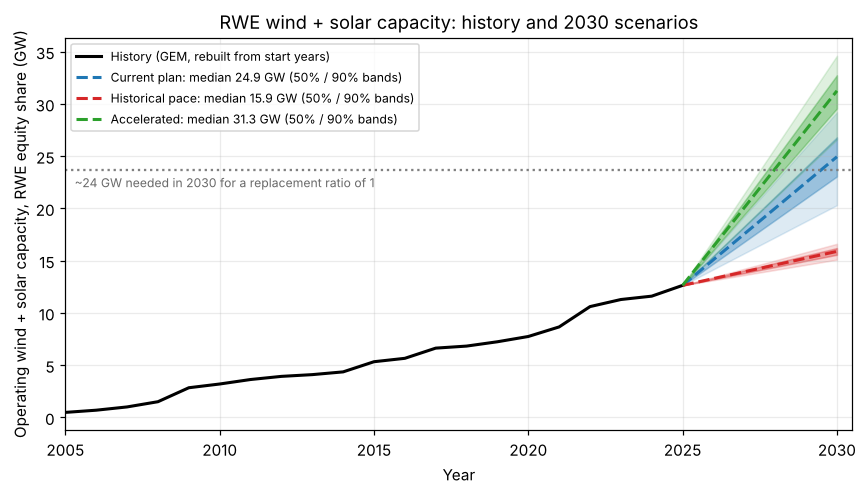

In [9]:
# capacity needed in 2030 for a replacement ratio of 1 (using the average CF of the pipeline)
cf_pipe = np.average(stage["cf"], weights=stage["GW"])
need_line = cap_now - old + FOSSIL_TWH / (cf_pipe * H_YEAR)

colors = {"Current plan": "tab:blue", "Historical pace": "tab:red", "Accelerated": "tab:green"}
fut_years = np.arange(now, TARGET + 1)
w = (fut_years - now) / (TARGET - now)                   # 0 today -> 1 in the target year

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(series.year, series.value, color="black", lw=2, label=f"History (GEM, rebuilt from start years)")
for name, draws in scen_draws.items():
    q05, q25, q50, q75, q95 = np.percentile(draws, [5, 25, 50, 75, 95])
    path = lambda qq: cap_now + (qq - cap_now) * w        # widen the band from today's value
    c = colors[name]
    ax.fill_between(fut_years, path(q05), path(q95), color=c, alpha=0.15)
    ax.fill_between(fut_years, path(q25), path(q75), color=c, alpha=0.35)
    ax.plot(fut_years, path(q50), color=c, lw=2, ls="--",
            label=f"{name}: median {q50:.1f} GW (50% / 90% bands)")
ax.axhline(need_line, color="grey", ls=":", lw=1.5)
ax.text(2005.3, need_line - 0.5, f"~{need_line:.0f} GW needed in {TARGET} for a replacement ratio of 1",
        fontsize=8, color="dimgrey", va="top")
ax.set(xlabel="Year", ylabel="Operating wind + solar capacity, RWE equity share (GW)",
       title=f"RWE wind + solar capacity: history and {TARGET} scenarios", xlim=(2005, TARGET + 0.5))
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig("fig_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

Under RWE's current pipeline, we estimate its wind + solar capacity at 24.9 GW in 2030 (90% interval 20.3–29.2 GW), i.e. a capacity-factor-adjusted replacement ratio of 1.11 (0.71–1.48) against the coal and gas it must retire. A simple trend failed our back-test: the linear band caught only 1 of 5 held-out years (2021–2025). Most of the range comes from how much of the pre-construction pipeline gets built in time. The scenario gap is even bigger: if RWE keeps building at its historical pace (0.73 GW/yr), it only reaches 15.9 GW and a ratio of 0.32, so covering the coal exit becomes exceptionally unlikely. Limitations: ownership is incomplete in GEM (28% of RWE units with a parent), capacity factors are fixed averages, and acquired assets count as if RWE built them.

**Your answer (Q7):**

"Because the range is this wide, the decision that changes is whether to treat RWE's 2030 coal exit as covered: we would only call it on track if RWE shows its build rate is going up to more than 2 GW a year (about 3 times its past pace), so investors should engage on project-level delivery milestones instead of trusting the headline pipeline." 